# Returns disposition defects: DMAIC analysis notebook

This steps through the Measure, Analyze, Improve and Control work. All data is synthetic (made by
`src/generate_data.py`). None of it comes from Amazon or any employer. Run `python src/run_all.py` first so
`data/returns_dmaic.db` exists, since the notebook reads from it.

In [1]:
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
con = sqlite3.connect(ROOT / 'data' / 'returns_dmaic.db')
sql = lambda name: pd.read_sql_query((ROOT / 'sql' / name).read_text(), con)
pd.set_option('display.width', 140)

## Measure: data quality and baseline (DPMO, sigma, first-pass yield)

In [2]:
pd.read_csv(ROOT / 'data' / 'processed' / 'data_quality_log.csv')

,table,check,rows
0,returns_units,raw rows,151098
1,returns_units,duplicate unit rows removed,180
2,returns_units,category variants standardized,400
3,returns_units,negative prices corrected (abs),12
4,returns_units,missing prices imputed (category median),350
5,returns_units,missing shift derived from received hour,250
6,returns_units,clean rows,150918
7,unit_cycle_stages,rows with negative stage time set to NULL,25
8,audits,duplicate audit rows removed,15
9,audits,orphan audits removed (no matching unit),8


In [3]:
sql('02_baseline_defect_rate_dpmo_sigma.sql')

,phase,site_id,audited_units,defects,defect_rate,dpmo,first_pass_yield,sigma_level
0,Baseline,NETWORK,10636,725,0.0682,68165.0,0.9059,2.98
1,Baseline,RC-CENTRAL,2646,224,0.0847,84656.0,0.8666,2.87
2,Baseline,RC-EAST,2855,183,0.0641,64098.0,0.9205,3.02
3,Baseline,RC-SOUTH,1909,113,0.0592,59193.0,0.9183,3.06
4,Baseline,RC-WEST,3226,205,0.0635,63546.0,0.9179,3.02
5,Pilot,NETWORK,2854,133,0.0466,46601.0,0.9331,3.17
6,Pilot,RC-CENTRAL,1081,28,0.0259,25902.0,0.9556,3.44
7,Pilot,RC-EAST,598,40,0.0669,66890.0,0.9147,2.99
8,Pilot,RC-SOUTH,418,26,0.0622,62201.0,0.9187,3.03
9,Pilot,RC-WEST,757,39,0.0515,51519.0,0.9234,3.13


In [4]:
ct = sql('05_cycle_time_percentiles.sql')
ct.pivot(index='month', columns='site_id', values='p90_hrs')

site_id,RC-CENTRAL,RC-EAST,RC-SOUTH,RC-WEST
month,,,,
2025-07,14.28,12.88,14.86,13.66
2025-08,15.22,13.41,14.39,13.61
2025-09,13.75,12.99,14.12,13.43
2025-10,16.40,14.87,17.00,15.86
2025-11,20.57,18.52,20.53,18.76
2025-12,28.91,26.74,29.59,27.29
2026-01,43.93,37.32,42.08,38.24
2026-02,23.32,21.59,23.63,22.34
2026-03,16.42,15.13,18.06,16.35


## Analyze: Pareto and stratification

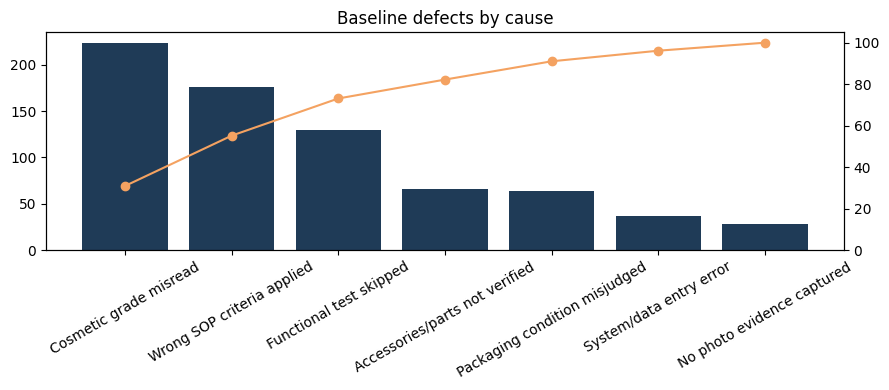

,defect_cause,defects,leakage_usd_in_sample,share,cumulative_share
0,Cosmetic grade misread,224,3297.97,0.3090,0.3090
1,Wrong SOP criteria applied,176,4655.53,0.2428,0.5517
2,Functional test skipped,130,2200.79,0.1793,0.7310
3,Accessories/parts not verified,66,839.43,0.0910,0.8221
4,Packaging condition misjudged,64,617.28,0.0883,0.9103
5,System/data entry error,37,664.22,0.0510,0.9614
6,No photo evidence captured,28,436.99,0.0386,1.0000


In [5]:
par = sql('03_defect_pareto_by_cause.sql')
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(par.defect_cause, par.defects, color='#1f3b57')
ax2 = ax.twinx(); ax2.plot(par.defect_cause, par.cumulative_share * 100, color='#f4a261', marker='o')
ax2.set_ylim(0, 105); ax.tick_params(axis='x', rotation=30)
ax.set_title('Baseline defects by cause'); plt.tight_layout(); plt.show()
par

In [6]:
seg = sql('04_defect_rate_by_segment.sql')
seg[seg.dimension.isin(['Shift', 'Tenure band', 'Site', 'Photo step done'])]

,dimension,segment,audited_units,defects,defect_rate,index_vs_network
22,Photo step done,No,2952,258,0.0874,1.28
23,Photo step done,Yes,7684,467,0.0608,0.89
24,Shift,Night,2132,187,0.0877,1.29
25,Shift,Swing,3739,244,0.0653,0.96
26,Shift,Day,4765,294,0.0617,0.91
27,Site,RC-CENTRAL,2646,224,0.0847,1.24
28,Site,RC-EAST,2855,183,0.0641,0.94
29,Site,RC-WEST,3226,205,0.0635,0.93
30,Site,RC-SOUTH,1909,113,0.0592,0.87
31,Tenure band,0-29 days,727,96,0.1320,1.94


### Root-cause check: logistic regression on baseline audits

In [7]:
aud = pd.read_sql_query('SELECT * FROM v_audited', con)
b = aud[aud.phase == 'Baseline'].assign(
    tenure_lt30=lambda d: (d.tenure_days < 30).astype(int),
    tenure_30_89=lambda d: d.tenure_days.between(30, 89).astype(int),
    electronics=lambda d: (d.category == 'Electronics').astype(int),
    true_open_box=lambda d: (d.audited_disposition == 'OPEN_BOX').astype(int),
    night_shift=lambda d: (d['shift'] == 'Night').astype(int),
    swing_shift=lambda d: (d['shift'] == 'Swing').astype(int),
    no_photo_step=lambda d: (d.photo_step_done == 0).astype(int),
    peak_backlog_dec_jan=lambda d: d.month.isin(['2025-12', '2026-01']).astype(int))
fit = smf.logit('is_defect ~ tenure_lt30 + tenure_30_89 + electronics + true_open_box + night_shift + swing_shift'
                ' + no_photo_step + peak_backlog_dec_jan', data=b).fit(disp=False)
pd.DataFrame({'odds_ratio': np.exp(fit.params), 'p_value': fit.pvalues}).round(4)

,odds_ratio,p_value
Intercept,0.0343,0.0000
tenure_lt30,2.4183,0.0000
tenure_30_89,1.3926,0.0033
electronics,1.6601,0.0000
true_open_box,1.9164,0.0000
night_shift,1.4080,0.0006
swing_shift,1.0536,0.5639
no_photo_step,1.5384,0.0000
peak_backlog_dec_jan,1.3115,0.0012


In [8]:
sql('10_value_stream_stage_times.sql')

,period,step_order,stage,value_added,mean_hrs,share_of_cycle
0,Control (May-Jun 2026),1,Dock wait,0,1.60,0.1558
1,Control (May-Jun 2026),2,Triage / receive scan,1,0.43,0.0414
2,Control (May-Jun 2026),3,Queue to grading,0,4.27,0.4162
3,Control (May-Jun 2026),4,Grading,1,0.48,0.0464
4,Control (May-Jun 2026),5,Routing to disposition,0,3.49,0.3401
5,Other baseline / pilot months,1,Dock wait,0,1.76,0.1571
6,Other baseline / pilot months,2,Triage / receive scan,1,0.42,0.0378
7,Other baseline / pilot months,3,Queue to grading,0,5.08,0.4530
8,Other baseline / pilot months,4,Grading,1,0.43,0.0380
9,Other baseline / pilot months,5,Routing to disposition,0,3.53,0.3142


## Improve: pilot at RC-CENTRAL vs comparison sites (two-proportion z-test)

In [9]:
sql('08_pilot_pre_post.sql')

,site_group,phase,units,audited_units,defects,upgrade_defects,defect_rate,leakage_usd_per_unit,waste_per_10k_units,mean_cycle_hrs,complaint_rate
0,Pilot site (RC-CENTRAL),Baseline,26295,2646,224,62,0.0847,2.058,49.1,15.84,0.0154
1,Pilot site (RC-CENTRAL),Pilot,5509,1081,28,8,0.0259,0.834,7.3,10.87,0.0062
2,Pilot site (RC-CENTRAL),Control,5667,573,11,3,0.0192,0.941,8.8,10.71,0.0081
3,Comparison sites,Baseline,79841,7990,501,136,0.0627,1.767,42.5,14.83,0.0110
4,Comparison sites,Pilot,17006,1773,105,29,0.0592,1.722,35.9,10.67,0.0110
5,Comparison sites,Control,16600,1626,54,14,0.0332,1.133,17.5,10.11,0.0064


In [10]:
def ztest(after, before):
    d = [aud.loc[after, 'is_defect'].sum(), aud.loc[before, 'is_defect'].sum()]
    n = [after.sum(), before.sum()]
    z, p = proportions_ztest(d, n, alternative='smaller')
    return {'rate_after': d[0] / n[0], 'rate_before': d[1] / n[1], 'z': z, 'p_value': p}

pilot = aud.is_pilot_site == 1
pd.DataFrame({
    'Pilot site: pilot vs baseline': ztest(pilot & (aud.phase == 'Pilot'), pilot & (aud.phase == 'Baseline')),
    'Comparison sites: same windows': ztest(~pilot & (aud.phase == 'Pilot'), ~pilot & (aud.phase == 'Baseline')),
    'Network: control vs baseline': ztest(aud.phase == 'Control', aud.phase == 'Baseline'),
}).T

,rate_after,rate_before,z,p_value
Pilot site: pilot vs baseline,0.025902,0.084656,-6.482586,4.508187e-11
Comparison sites: same windows,0.059222,0.062703,-0.549668,2.912736e-01
Network: control vs baseline,0.029559,0.068165,-6.857024,3.515480e-12


## Control: p-chart with recalculated limits

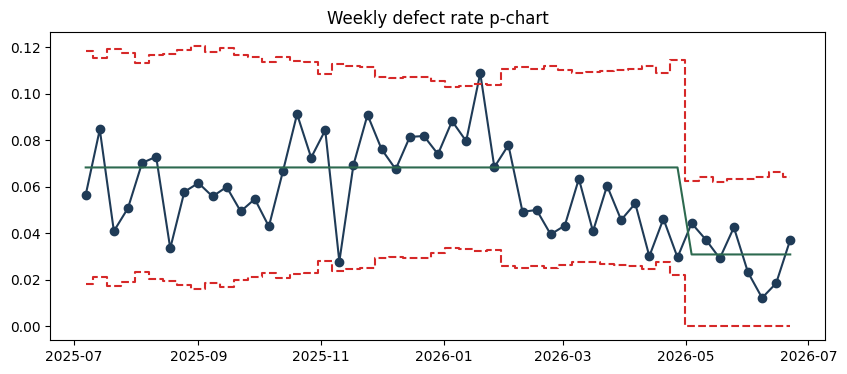

,audited_units,defects,rate
phase,,,
Baseline,10472,715,0.068277
Control,2008,62,0.030876
Pilot,2909,135,0.046408


In [11]:
w = sql('09_weekly_control_chart_feed.sql')
w = w[w.partial_week_flag == 0].copy()
w['week_start'] = pd.to_datetime(w.week_start)
for ph in ['Baseline', 'Control']:
    g = w[w.phase == ph]
    w.loc[w.phase == ph if ph == 'Control' else w.phase != 'Control', 'pbar'] = g.defects.sum() / g.audited_units.sum()
w['ucl'] = w.pbar + 3 * np.sqrt(w.pbar * (1 - w.pbar) / w.audited_units)
w['lcl'] = (w.pbar - 3 * np.sqrt(w.pbar * (1 - w.pbar) / w.audited_units)).clip(lower=0)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(w.week_start, w.defect_rate, marker='o', color='#1f3b57')
ax.step(w.week_start, w.ucl, where='mid', color='#d62828', ls='--'); ax.step(w.week_start, w.lcl, where='mid', color='#d62828', ls='--')
ax.plot(w.week_start, w.pbar, color='#2d6a4f'); ax.set_title('Weekly defect rate p-chart'); plt.show()
w.groupby('phase')[['audited_units', 'defects']].sum().assign(rate=lambda d: d.defects / d.audited_units)

In [12]:
pd.read_csv(ROOT / 'data' / 'processed' / 'capability.csv').round(3)

,phase,units,mean_hrs,p50_hrs,p95_hrs,usl_hrs,pct_over_usl,ppm_over_usl,ppk_lognormal
0,Baseline,106117,15.083,12.45,32.650,48.0,0.012,11619.250,0.852
1,Pilot,22513,10.717,9.90,18.274,48.0,0.000,88.838,1.522
2,Control,22263,10.259,9.56,17.030,48.0,0.000,0.000,1.619


In [13]:
pd.read_csv(ROOT / 'data' / 'processed' / 'impact_summary.csv')

,metric,value
0,Annualized units processed,150918.000000
1,Baseline defect rate,0.068165
2,Control defect rate,0.029559
3,Target defect rate (charter),0.035000
4,Incremental leakage per defect (USD),16.903136
5,Defects avoided per year (at control rate),5826.315131
6,Recovery value protected per year at control r...,98482.998996
7,Recovery value protected per year at target ra...,84602.796272
8,Baseline recovery rate (achieved / potential),0.957056
9,Control recovery rate (achieved / potential),0.974451


## What this shows

- The Measure tables give the baseline defect rate, DPMO and sigma, and the Pareto shows which causes lead.
- In the logistic regression, tenure under 30 days, open-box items, Electronics, no photo step, night shift and the Dec-Jan backlog all raise the odds of a misgrade.
- Testing the comparison sites over the same weeks is what separates the SOP fix from seasonality.
- The Control-period p-chart and capability table show the gain holding. The ongoing checks are in `docs/06_Control_Plan.md`.